# Notebook 5: SHAP Explainability & Clinical Decision Dashboard
## Pancreatic Cancer Multi-Omics Framework

**Purpose:** Full explainability suite for all 4 models + publication-ready dashboard

References: Lundberg & Lee (2017) SHAP; Lundberg et al. (2020) TreeExplainer — *Nature Machine Intelligence*

In [1]:
# !pip install shap xgboost matplotlib seaborn pandas numpy scikit-learn plotly lifelines
import os, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import shap
from xgboost import XGBClassifier
from lifelines import KaplanMeierFitter
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

shap.initjs()
print(f'SHAP version: {shap.__version__}')

SHAP version: 0.51.0


In [2]:
BASE_DIR = r'D:\CDAC_Project\PAN-DATASET'   # ← CHANGE TO YOUR DATASET ROOT
OUT_DIR  = os.path.join(BASE_DIR, 'model_outputs')
PREP_DIR = os.path.join(BASE_DIR, 'preprocessed')
DASH_DIR = os.path.join(OUT_DIR, 'dashboard_figures')
os.makedirs(DASH_DIR, exist_ok=True)

# Publication style
plt.rcParams.update({
    'font.family'      : 'DejaVu Sans',
    'font.size'        : 11,
    'axes.titlesize'   : 13,
    'axes.labelsize'   : 11,
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'figure.dpi'       : 150,
    'savefig.bbox'     : 'tight',
    'savefig.dpi'      : 300,
})
print('Config loaded.')

Config loaded.


## 1. Load Models and Feature Data

In [3]:
X_fused      = np.load(os.path.join(OUT_DIR, 'X_fused.npy'))
y_labels_raw = np.load(os.path.join(OUT_DIR, 'y_labels.npy'))
y_prob_m1    = np.load(os.path.join(OUT_DIR, 'y_prob_m1.npy'))
feat_names   = pd.read_csv(os.path.join(OUT_DIR,'feature_names.csv'), header=None)[0].tolist()
surv_scores  = pd.read_csv(os.path.join(OUT_DIR,'deepsurv_risk_scores.csv'), index_col=0)
perf_df      = pd.read_csv(os.path.join(OUT_DIR,'model_performance_summary.csv'))

m1 = XGBClassifier()
m1.load_model(os.path.join(OUT_DIR,'xgb_model1_detection.json'))

# Align all arrays to the same length — Model 1 may have used a subset of patients
n_samples = min(len(X_fused), len(y_labels_raw), len(y_prob_m1))
X_fused   = X_fused[:n_samples]
y_labels  = y_labels_raw[:n_samples].astype(int)
y_prob_m1 = y_prob_m1[:n_samples]
X_df      = pd.DataFrame(X_fused, columns=feat_names)

print(f'X_fused   : {X_fused.shape}')
print(f'y_labels  : {y_labels.shape}  classes={dict(zip(*np.unique(y_labels, return_counts=True)))}')
print(f'y_prob_m1 : {y_prob_m1.shape}')
print(f'feat_names: {len(feat_names)}')
print(f'Performance:\n{perf_df.to_string(index=False)}')


X_fused   : (128, 128)
y_labels  : (128,)  classes={np.int64(0): np.int64(64), np.int64(1): np.int64(64)}
y_prob_m1 : (128,)
feat_names: 128
Performance:
                      Model AUC-ROC Accuracy             F1
   Model 1: Early Detection  0.9990   0.9922         0.9922
Model 3: Treatment Response  0.9401        —         0.8678
 Model 4: DeepSurv Survival       —        — C-index=0.9481


## 2. SHAP TreeExplainer — Model 1 (Early Detection)
> *Lundberg, S.M. & Lee, S.I. (2017). A Unified Approach to Interpreting Model Predictions. NeurIPS 2017.*

In [4]:
print('Computing SHAP values for Model 1...')
explainer_m1 = shap.TreeExplainer(m1)

BATCH = 64
shap_batches = []
for start in range(0, len(X_df), BATCH):
    batch = X_df.iloc[start:start+BATCH]
    sv_b  = explainer_m1.shap_values(batch)
    if isinstance(sv_b, list):
        sv_b = sv_b[1]
    shap_batches.append(sv_b)

sv = np.vstack(shap_batches)

# Final alignment — all arrays must share same row count
min_len   = min(len(sv), len(X_df), len(y_labels))
sv        = sv[:min_len]
X_df      = X_df.iloc[:min_len].reset_index(drop=True)
y_labels  = y_labels[:min_len]
y_prob_m1 = y_prob_m1[:min_len]
X_fused   = X_fused[:min_len]

shap_df = pd.DataFrame(sv, columns=feat_names)
shap_df.to_csv(os.path.join(OUT_DIR,'shap_values_m1.csv'))
print(f'SHAP values : {shap_df.shape}')
print(f'X_df        : {X_df.shape}')
print(f'y_labels    : {y_labels.shape}')
print('All arrays aligned. Saved: shap_values_m1.csv')


Computing SHAP values for Model 1...
SHAP values : (128, 128)
X_df        : (128, 128)
y_labels    : (128,)
All arrays aligned. Saved: shap_values_m1.csv


In [5]:
# ── Mean |SHAP| per feature ───────────────────────────────────────────────
mean_shap    = np.abs(sv).mean(axis=0)
shap_imp_df  = pd.DataFrame({'feature': feat_names, 'mean_abs_shap': mean_shap})
shap_imp_df  = shap_imp_df.sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)
shap_imp_df.to_csv(os.path.join(OUT_DIR,'shap_feature_importance.csv'), index=False)
print(f'Top 10 features by mean |SHAP|:')
print(shap_imp_df.head(10).to_string(index=False))

Top 10 features by mean |SHAP|:
  feature  mean_abs_shap
 fused_71       0.679440
 fused_34       0.476965
  fused_5       0.422713
 fused_31       0.409363
 fused_30       0.276168
 fused_73       0.244126
fused_124       0.240716
 fused_61       0.135185
 fused_14       0.123259
 fused_37       0.106362


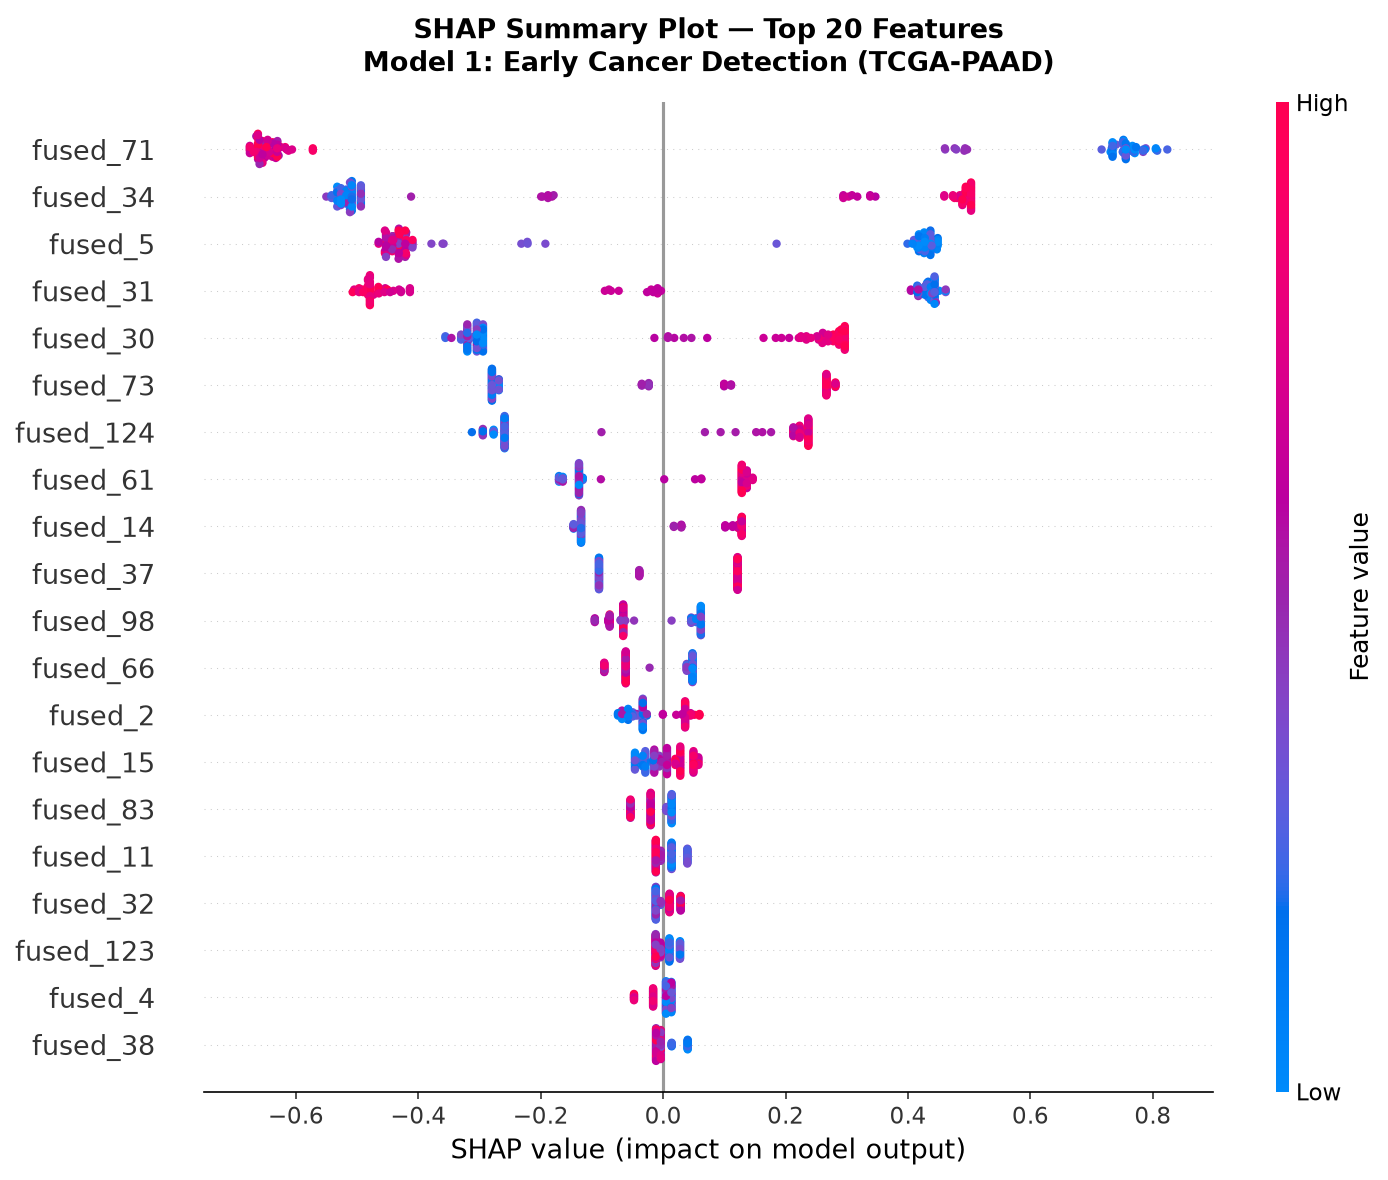

Saved: shap_summary_beeswarm.png


In [6]:
# ── SHAP Summary (Beeswarm) plot — Publication Figure 1 ──────────────────
top_n = 20
top_feats = shap_imp_df['feature'].head(top_n).tolist()

fig, ax = plt.subplots(figsize=(10, 8))
shap.summary_plot(
    sv[:, [feat_names.index(f) for f in top_feats]],
    X_df[top_feats],
    feature_names=top_feats,
    show=False, plot_size=None, color_bar=True
)
plt.title(f'SHAP Summary Plot — Top {top_n} Features\nModel 1: Early Cancer Detection (TCGA-PAAD)',
          fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(os.path.join(DASH_DIR,'shap_summary_beeswarm.png'), dpi=300)
plt.show()
print('Saved: shap_summary_beeswarm.png')

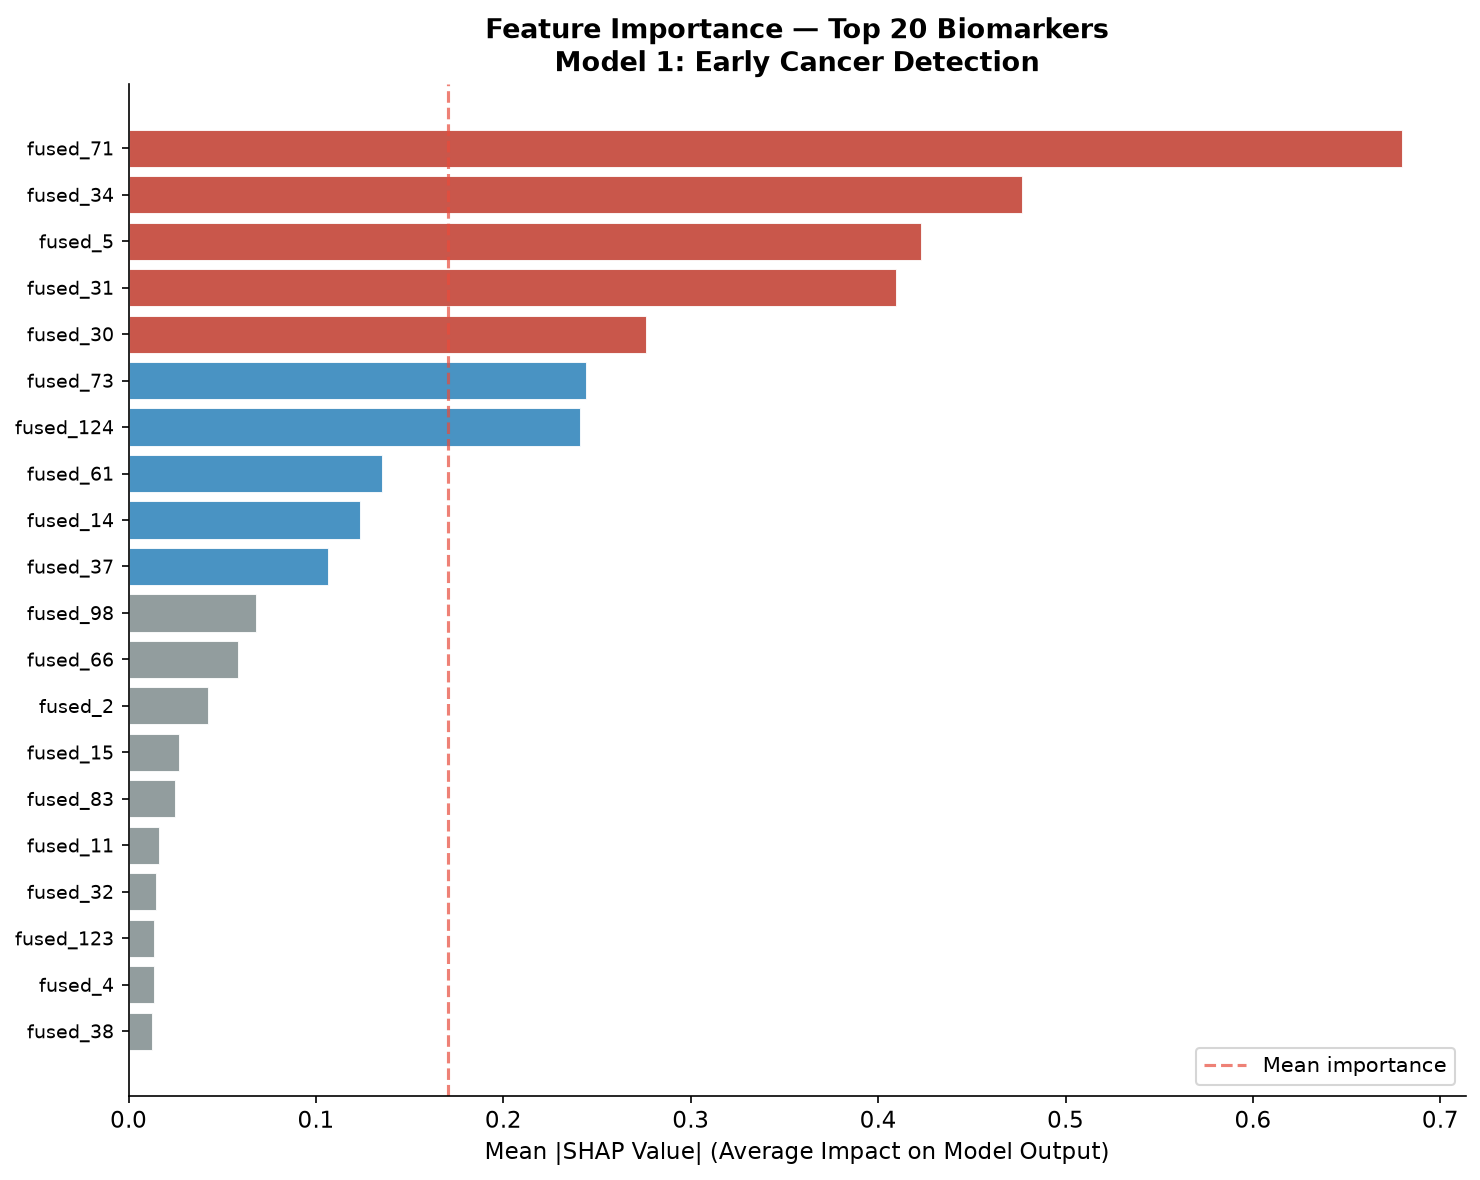

Saved: shap_feature_importance_bar.png


In [7]:
# ── SHAP Bar plot (mean |SHAP|) — Publication Figure 2 ───────────────────
fig, ax = plt.subplots(figsize=(10, 8))
colors_bar = ['#c0392b' if i < 5 else '#2980b9' if i < 10 else '#7f8c8d'
              for i in range(top_n)]
bars = ax.barh(range(top_n), shap_imp_df['mean_abs_shap'].head(top_n).values[::-1],
               color=colors_bar[::-1], alpha=0.85, edgecolor='white', linewidth=0.5)
ax.set_yticks(range(top_n))
ax.set_yticklabels(shap_imp_df['feature'].head(top_n).values[::-1], fontsize=9)
ax.set_xlabel('Mean |SHAP Value| (Average Impact on Model Output)', fontsize=11)
ax.set_title(f'Feature Importance — Top {top_n} Biomarkers\nModel 1: Early Cancer Detection',
             fontsize=13, fontweight='bold')
ax.axvline(x=shap_imp_df['mean_abs_shap'].head(top_n).mean(), color='#e74c3c',
           linestyle='--', alpha=0.7, label='Mean importance')
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(DASH_DIR,'shap_feature_importance_bar.png'), dpi=300)
plt.show()
print('Saved: shap_feature_importance_bar.png')

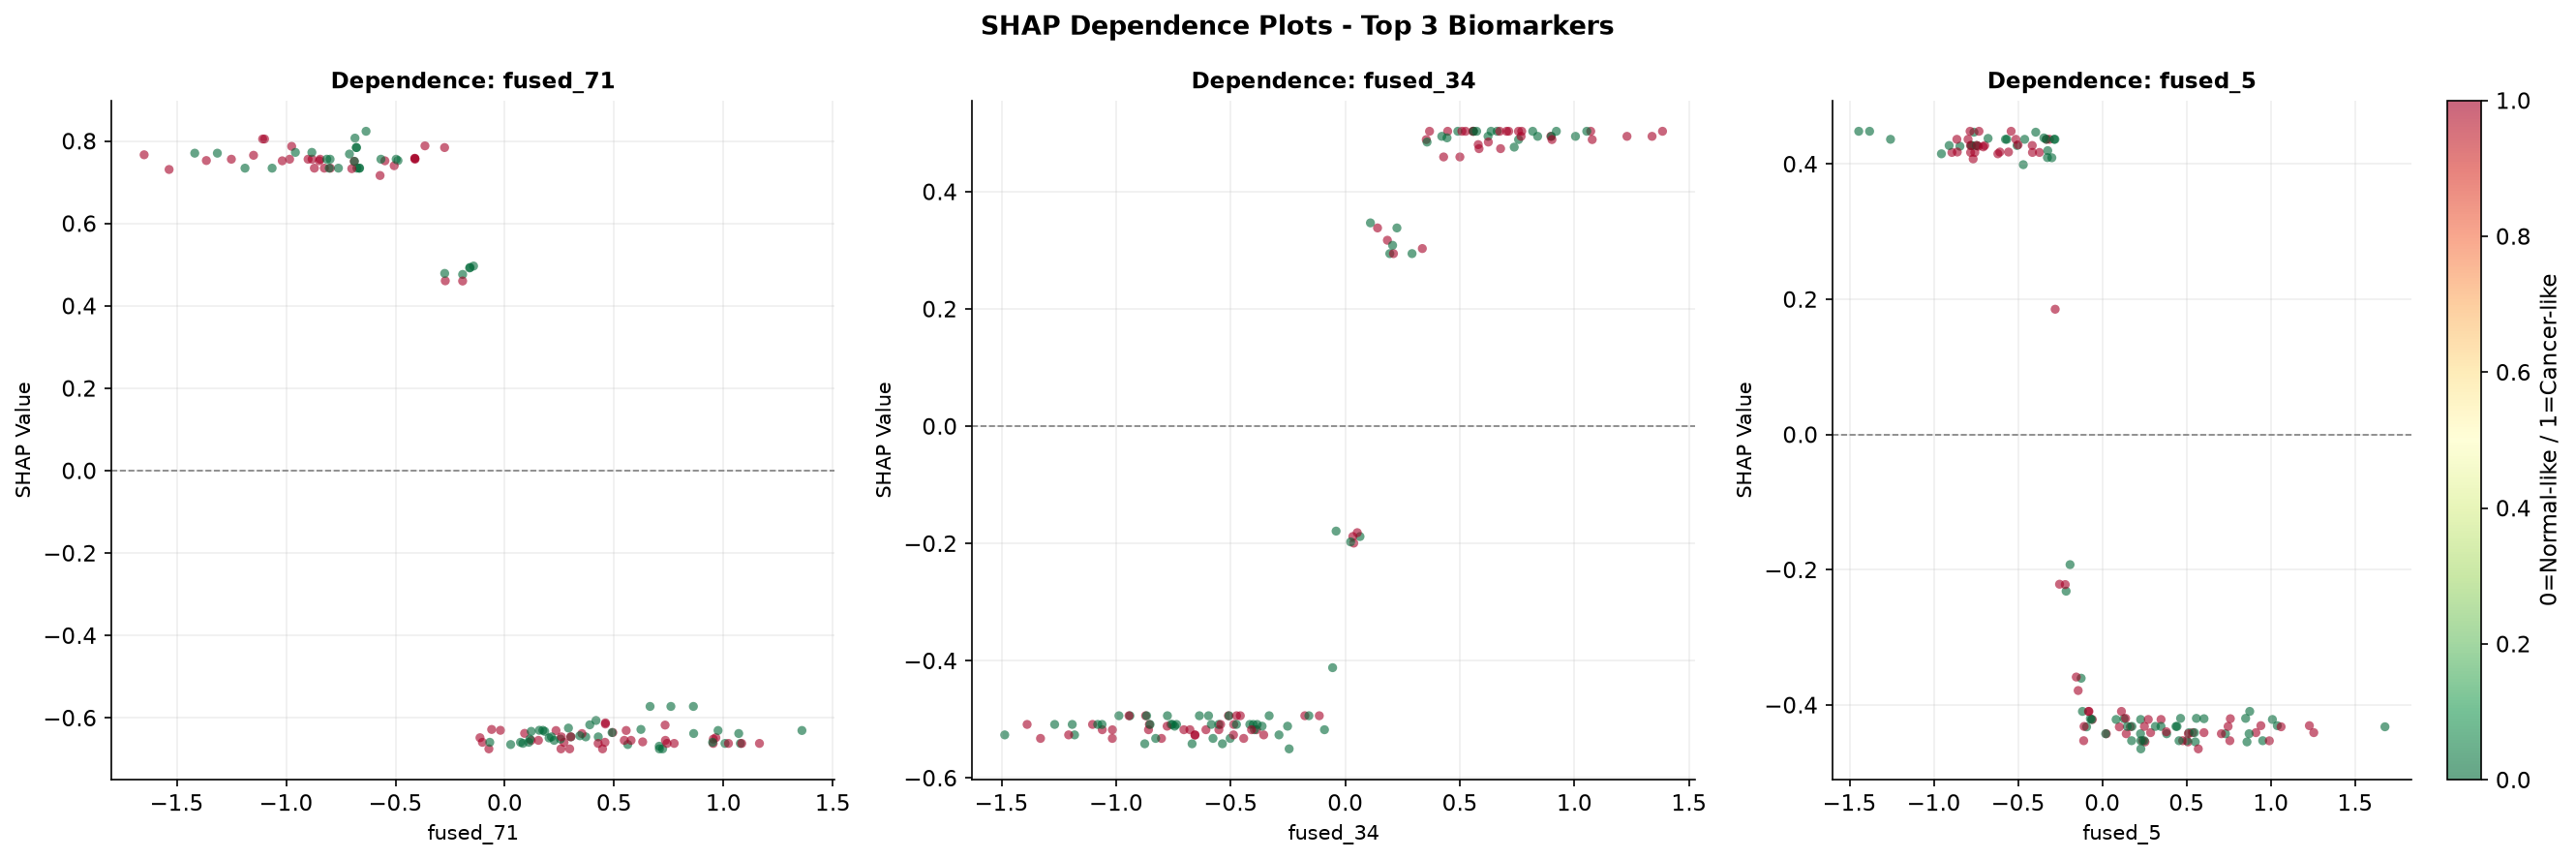

Saved: shap_dependence_plots.png


In [8]:
top3 = shap_imp_df['feature'].head(3).tolist()
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, feat in zip(axes, top3):
    fidx      = feat_names.index(feat)
    feat_vals = X_df[feat].values
    shap_vals = sv[:, fidx]
    lbl_vals  = y_labels
    n = min(len(feat_vals), len(shap_vals), len(lbl_vals))
    feat_vals = feat_vals[:n]
    shap_vals = shap_vals[:n]
    lbl_vals  = lbl_vals[:n].astype(float)

    sc = ax.scatter(feat_vals, shap_vals,
                    c=lbl_vals, cmap=plt.cm.RdYlGn_r,
                    alpha=0.6, s=20, edgecolors='none',
                    vmin=0, vmax=1)
    ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
    ax.set_xlabel(feat, fontsize=10)
    ax.set_ylabel('SHAP Value', fontsize=10)
    ax.set_title(f'Dependence: {feat}', fontsize=11, fontweight='bold')
    ax.grid(alpha=0.2)

fig.colorbar(sc, ax=axes[-1], label='0=Normal-like / 1=Cancer-like')
plt.suptitle('SHAP Dependence Plots - Top 3 Biomarkers', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(DASH_DIR,'shap_dependence_plots.png'), dpi=300)
plt.show()
print('Saved: shap_dependence_plots.png')


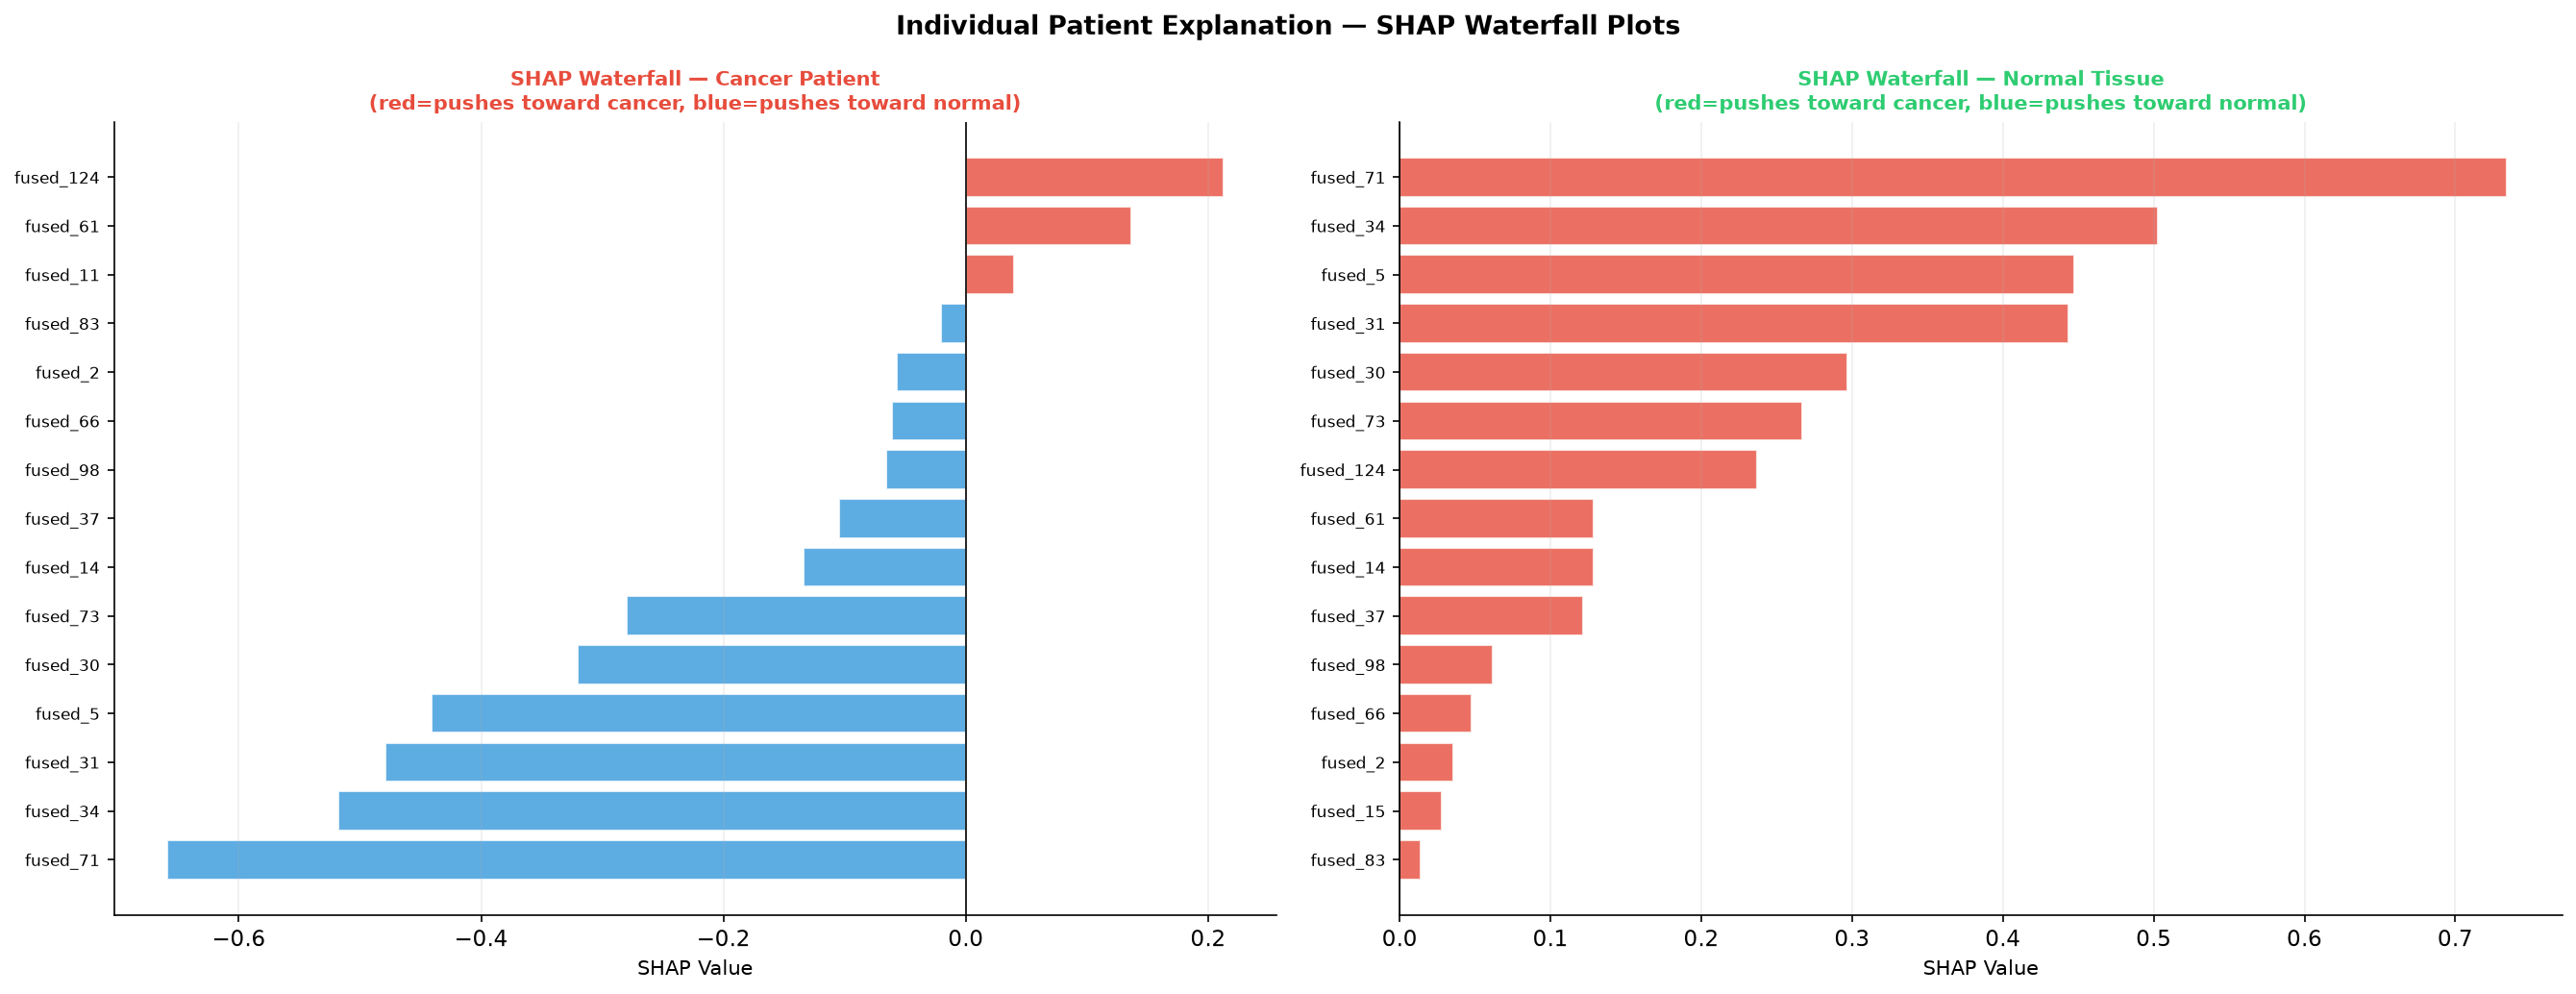

Saved: shap_waterfall_individual.png


In [9]:
# ── SHAP Waterfall for individual patients — Figure 4 ────────────────────
# Show one cancer and one normal patient
cancer_idx = np.where(y_labels == 1)[0][0]
normal_idx = np.where(y_labels == 0)[0][0]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, pat_idx, pat_label, color in zip(
    axes, [cancer_idx, normal_idx], ['Cancer Patient', 'Normal Tissue'], ['#e74c3c','#2ecc71']):
    top_feat_idx = np.argsort(np.abs(sv[pat_idx]))[-15:]
    vals    = sv[pat_idx][top_feat_idx]
    feats   = [feat_names[i] for i in top_feat_idx]
    sorted_order = np.argsort(vals)
    vals  = vals[sorted_order]
    feats = [feats[i] for i in sorted_order]
    bar_colors = ['#e74c3c' if v > 0 else '#3498db' for v in vals]
    ax.barh(range(len(vals)), vals, color=bar_colors, alpha=0.8, edgecolor='white')
    ax.set_yticks(range(len(vals)))
    ax.set_yticklabels(feats, fontsize=8)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('SHAP Value', fontsize=10)
    ax.set_title(f'SHAP Waterfall — {pat_label}\n(red=pushes toward cancer, blue=pushes toward normal)',
                 fontsize=10, fontweight='bold', color=color)
    ax.grid(axis='x', alpha=0.2)
plt.suptitle('Individual Patient Explanation — SHAP Waterfall Plots', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(DASH_DIR,'shap_waterfall_individual.png'), dpi=300)
plt.show()
print('Saved: shap_waterfall_individual.png')

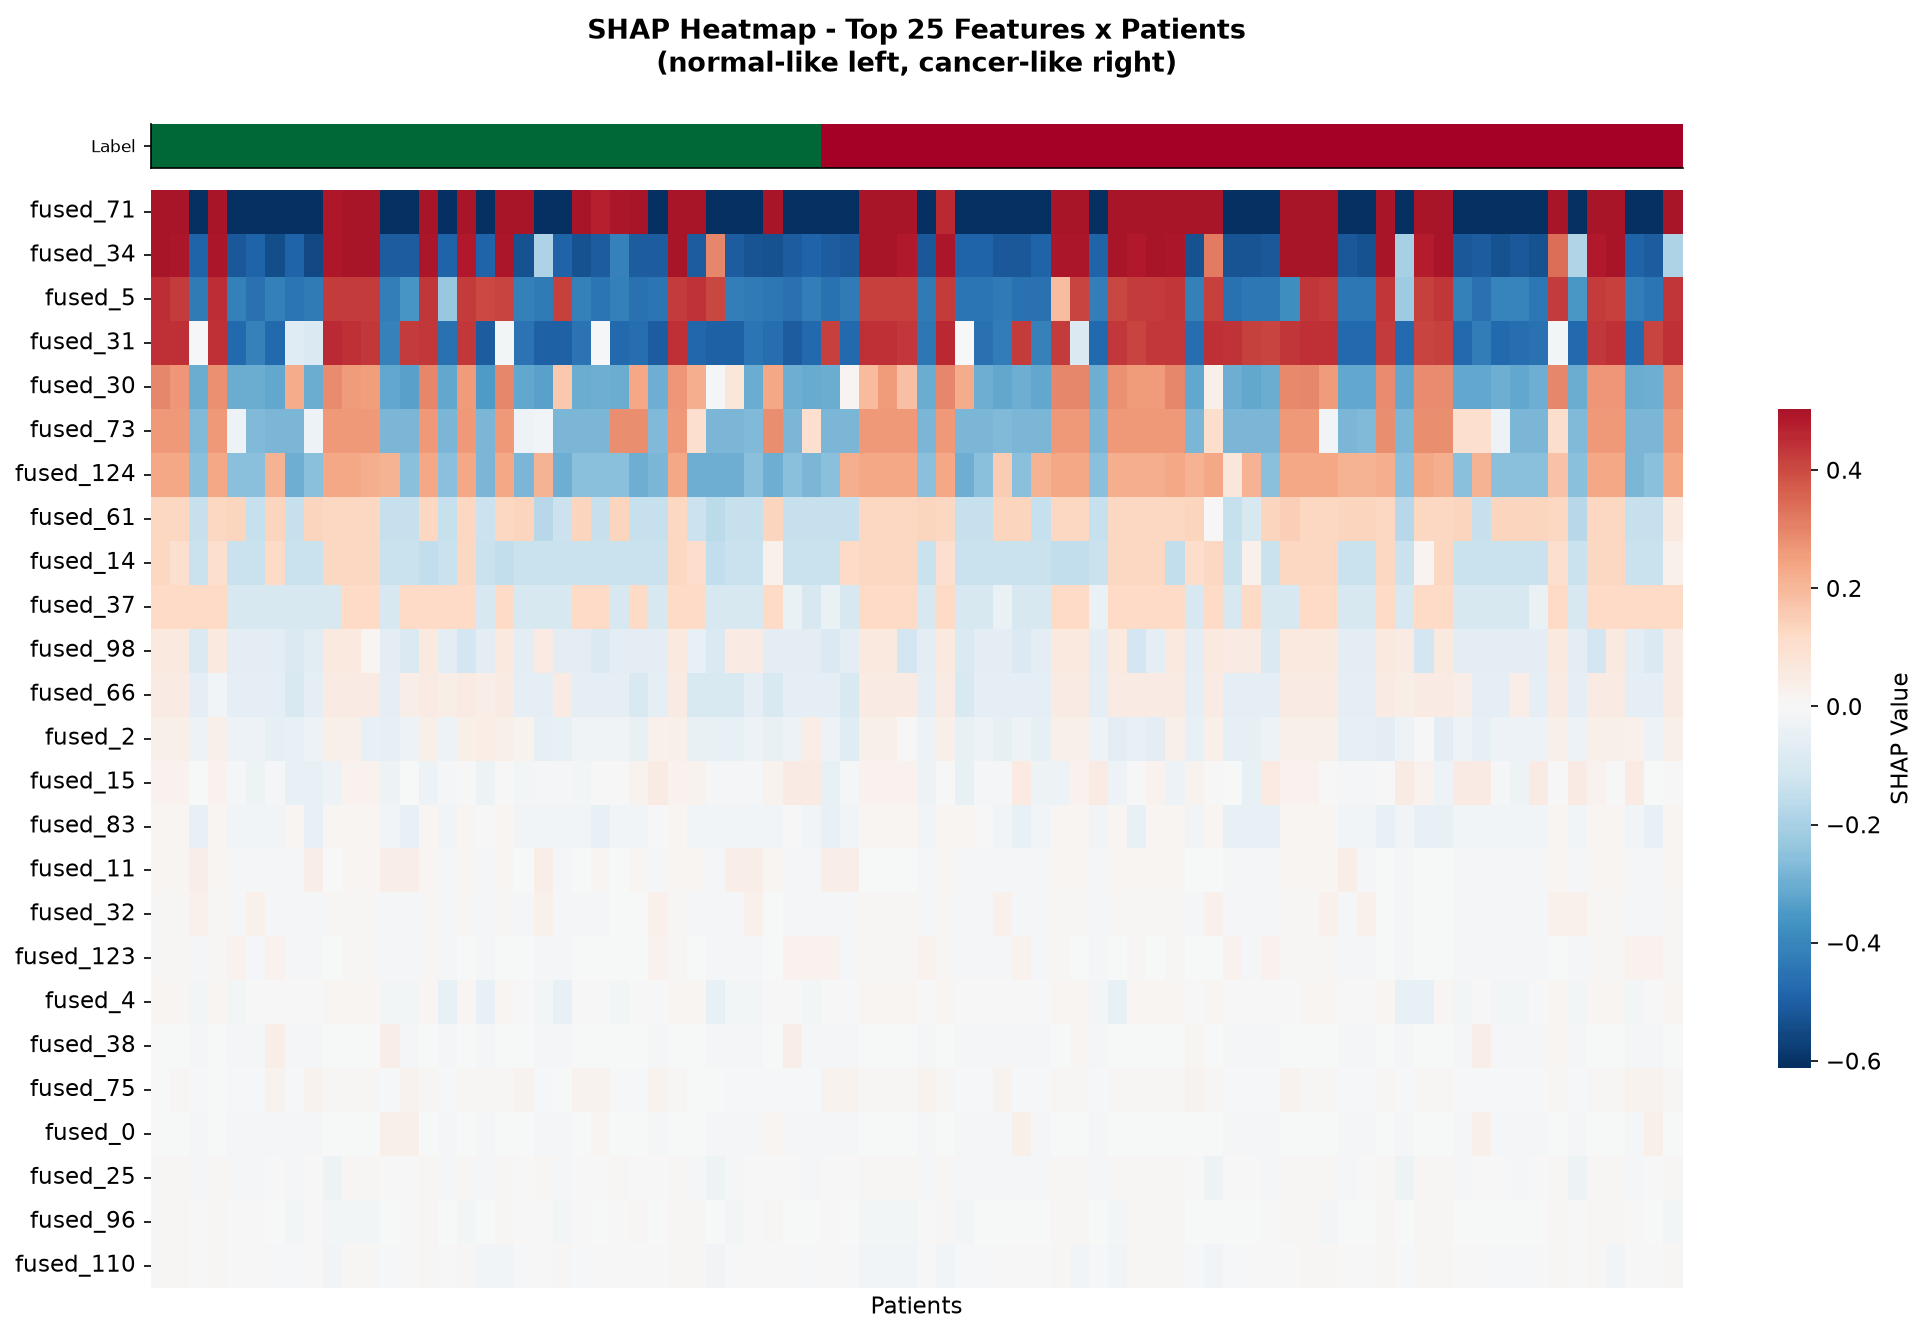

Saved: shap_heatmap_patients.png


In [10]:
n_show   = min(80, len(X_df))
feat_sel = shap_imp_df['feature'].head(25).tolist()
sv_sel   = shap_df[feat_sel].values[:n_show]
lbl_show = y_labels[:n_show]
order    = np.argsort(lbl_show)

fig, ax = plt.subplots(figsize=(14, 9))
sns.heatmap(sv_sel[order].T,
            cmap='RdBu_r', center=0,
            xticklabels=False, yticklabels=feat_sel,
            ax=ax, cbar_kws={'label':'SHAP Value', 'shrink':0.6},
            linewidths=0, robust=True)

label_bar = lbl_show[order].reshape(1, -1).astype(float)
ax2 = ax.inset_axes([0, 1.02, 1, 0.04])
ax2.imshow(label_bar, cmap=plt.cm.RdYlGn_r, aspect='auto', vmin=0, vmax=1)
ax2.set_xticks([])
ax2.set_yticks([0])
ax2.set_yticklabels(['Label'], fontsize=8)

ax.set_title('SHAP Heatmap - Top 25 Features x Patients\n(normal-like left, cancer-like right)',
             fontsize=13, fontweight='bold', pad=25)
ax.set_xlabel('Patients')
plt.tight_layout()
plt.savefig(os.path.join(DASH_DIR,'shap_heatmap_patients.png'), dpi=300)
plt.show()
print('Saved: shap_heatmap_patients.png')


## 3. Clinical Decision Dashboard — Publication Figure

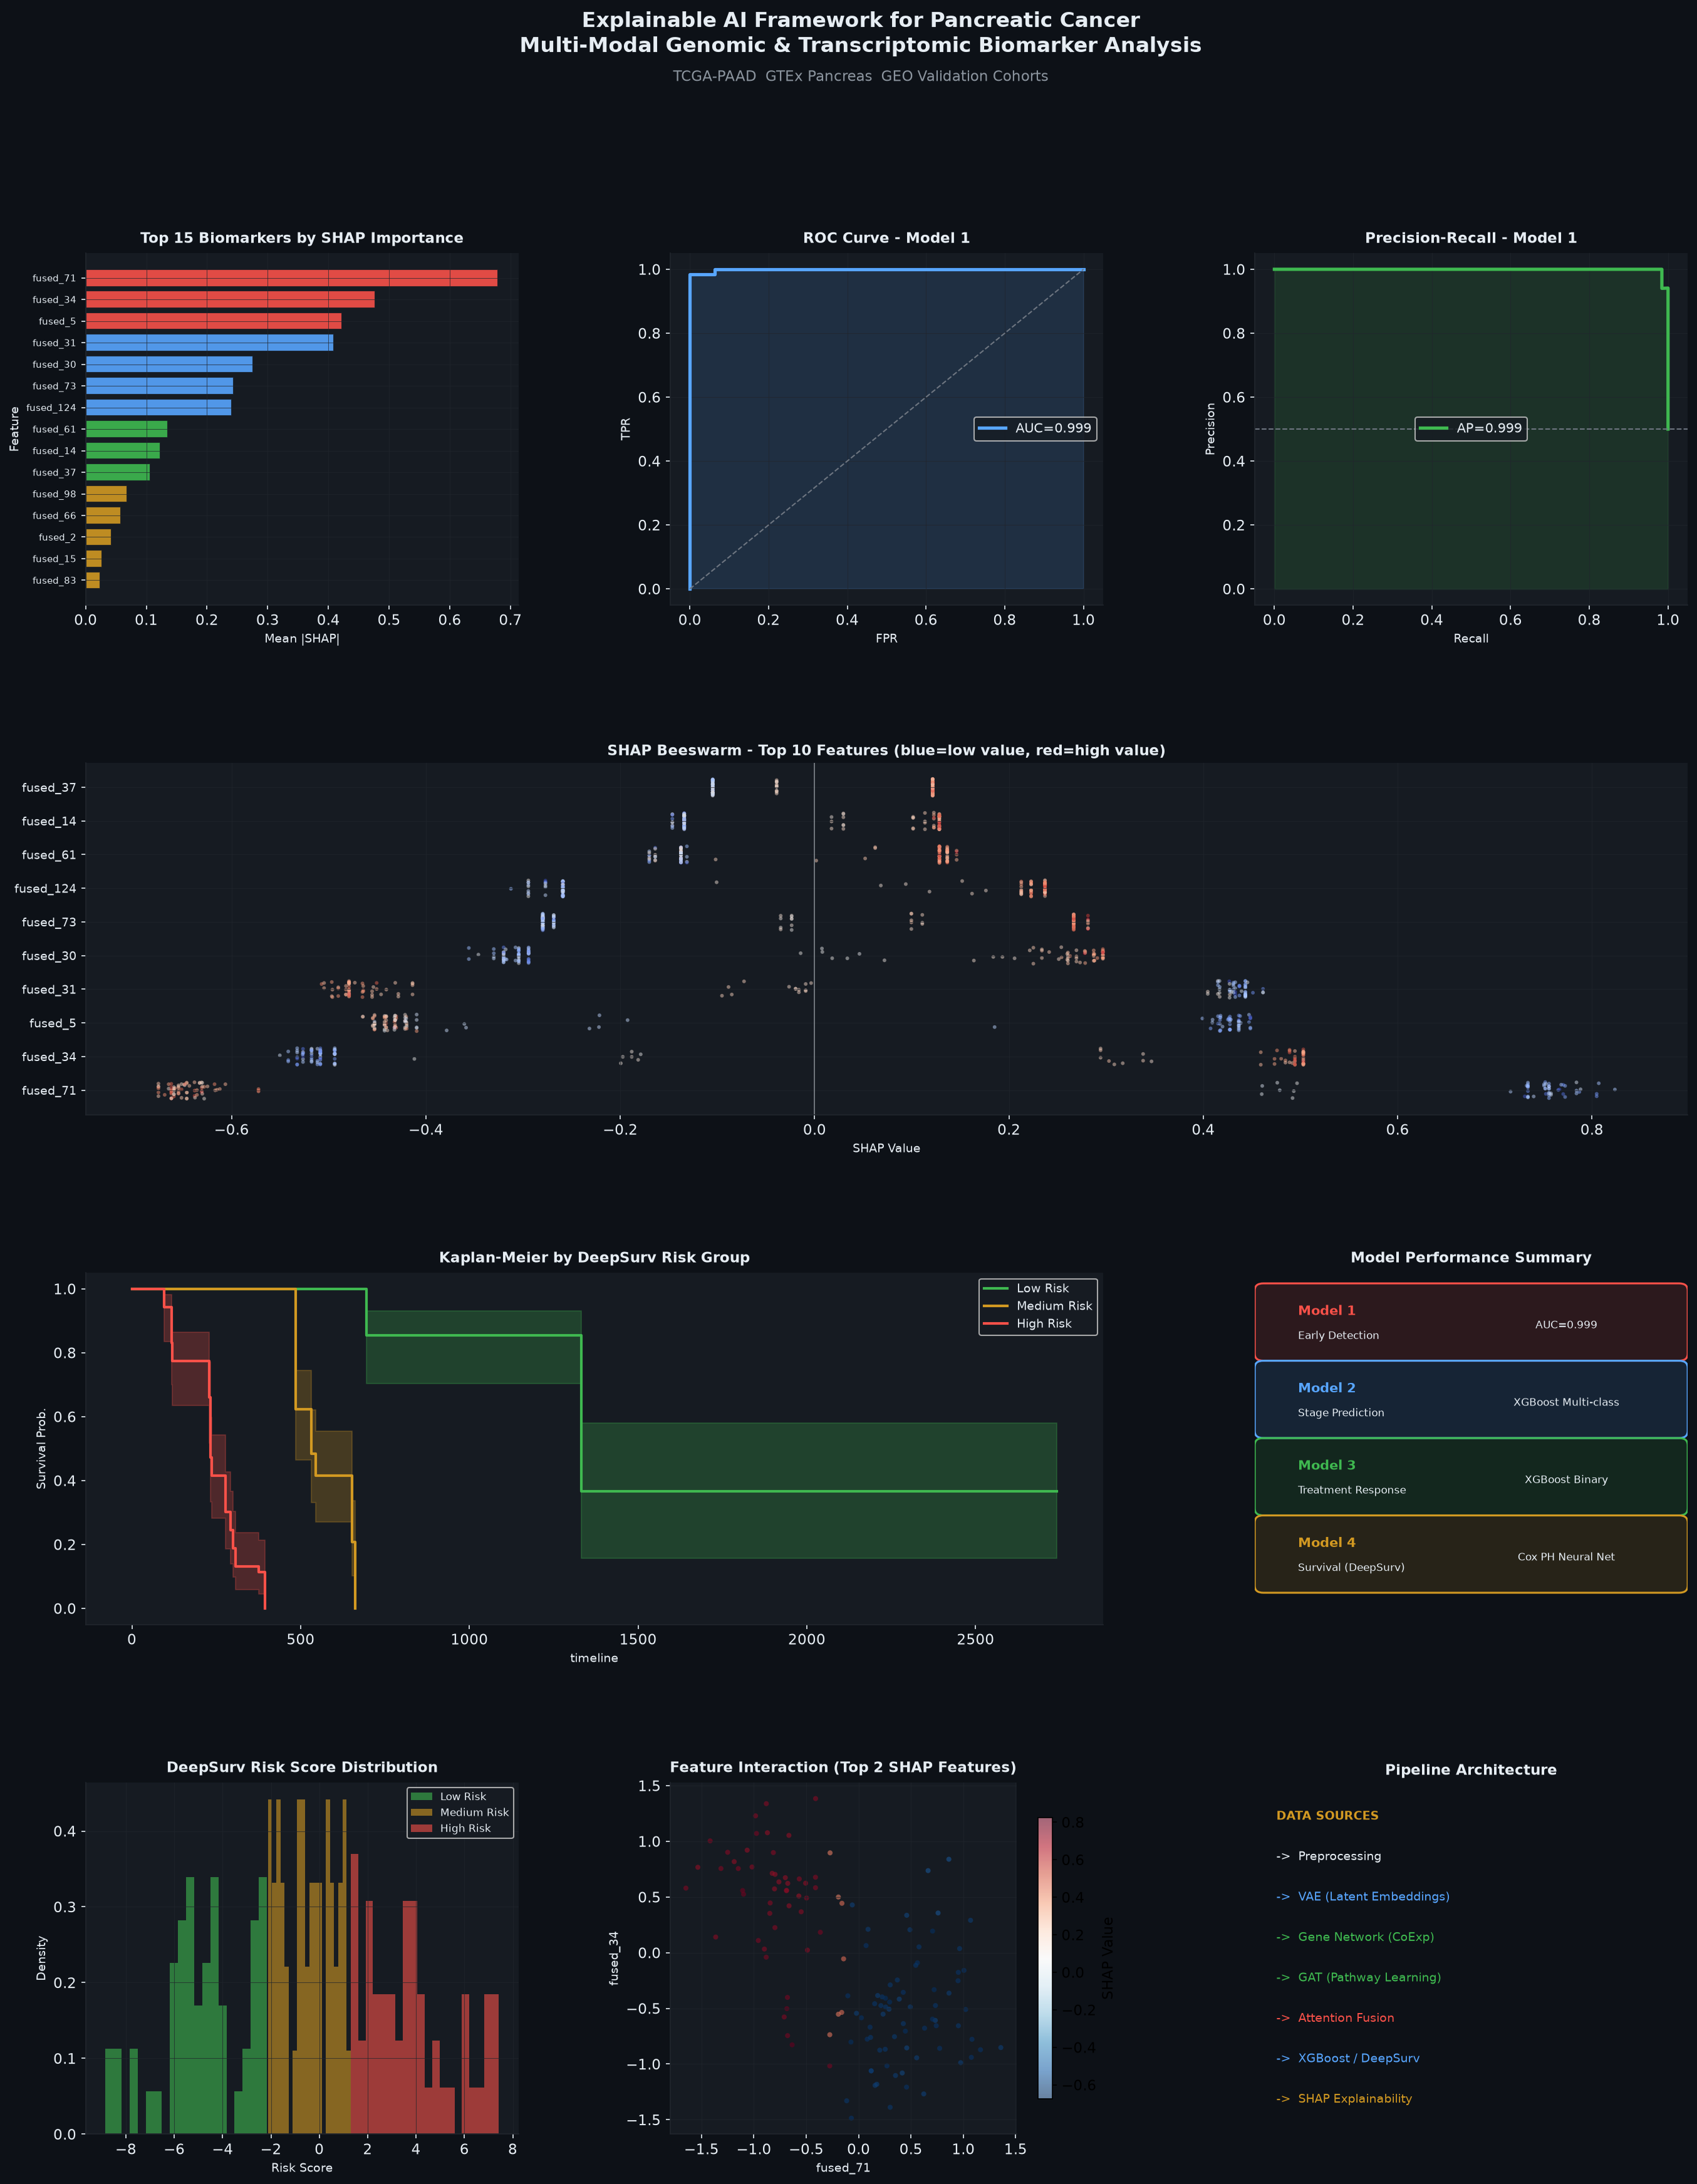

Saved: clinical_decision_dashboard.png


In [11]:
import matplotlib.patches as mpatches
from sklearn.metrics import roc_curve, auc as sklearn_auc
from sklearn.metrics import precision_recall_curve, average_precision_score
from lifelines import KaplanMeierFitter

unique_lbl  = np.unique(y_labels)
can_do_roc  = len(unique_lbl) == 2
roc_auc_val = 0.5
ap_val      = float(y_labels.mean())
if can_do_roc:
    fpr, tpr, _ = roc_curve(y_labels, y_prob_m1)
    roc_auc_val = sklearn_auc(fpr, tpr)
    prec, rec, _= precision_recall_curve(y_labels, y_prob_m1)
    ap_val      = average_precision_score(y_labels, y_prob_m1)
else:
    print(f'WARNING: y_labels has only classes {unique_lbl}. ROC/PR panels will show N/A.')

DARK_BG  = '#0d1117'
PANEL_BG = '#161b22'
TEXT_COL = '#e6edf3'
ACC_BLUE = '#58a6ff'
ACC_GREEN= '#3fb950'
ACC_RED  = '#f85149'
ACC_GOLD = '#d29922'
GRID_COL = '#21262d'
km_colors = {'Low Risk': ACC_GREEN, 'Medium Risk': ACC_GOLD, 'High Risk': ACC_RED}

def style_ax(ax, title='', xlabel='', ylabel=''):
    ax.set_facecolor(PANEL_BG)
    ax.tick_params(colors=TEXT_COL)
    ax.xaxis.label.set_color(TEXT_COL)
    ax.yaxis.label.set_color(TEXT_COL)
    ax.title.set_color(TEXT_COL)
    for spine in ax.spines.values():
        spine.set_color(GRID_COL)
    ax.grid(color=GRID_COL, linewidth=0.5, alpha=0.7)
    if title:  ax.set_title(title,  fontsize=11, fontweight='bold', color=TEXT_COL, pad=8)
    if xlabel: ax.set_xlabel(xlabel, fontsize=9,  color=TEXT_COL)
    if ylabel: ax.set_ylabel(ylabel, fontsize=9,  color=TEXT_COL)
    return ax

fig = plt.figure(figsize=(22, 26))
fig.patch.set_facecolor(DARK_BG)
gs  = gridspec.GridSpec(4, 3, figure=fig, hspace=0.45, wspace=0.35)

# Panel 1: Feature importance
ax1 = fig.add_subplot(gs[0, 0])
style_ax(ax1, 'Top 15 Biomarkers by SHAP Importance', 'Mean |SHAP|', 'Feature')
top15  = shap_imp_df.head(15)
bar_c  = ([ACC_RED]*3 + [ACC_BLUE]*4 + [ACC_GREEN]*3 + [ACC_GOLD]*5)[:15]
ax1.barh(range(15), top15['mean_abs_shap'].values[::-1],
         color=bar_c[::-1], alpha=0.9, edgecolor=PANEL_BG)
ax1.set_yticks(range(15))
ax1.set_yticklabels(top15['feature'].values[::-1], fontsize=7, color=TEXT_COL)

# Panel 2: ROC
ax2 = fig.add_subplot(gs[0, 1])
style_ax(ax2, 'ROC Curve - Model 1', 'FPR', 'TPR')
if can_do_roc:
    ax2.fill_between(fpr, tpr, alpha=0.15, color=ACC_BLUE)
    ax2.plot(fpr, tpr, color=ACC_BLUE, lw=2.5, label=f'AUC={roc_auc_val:.3f}')
    ax2.plot([0,1],[0,1],'--', color='#6e7681', lw=1)
    ax2.legend(fontsize=10, facecolor=PANEL_BG, labelcolor=TEXT_COL)
else:
    ax2.text(0.5, 0.5, 'Single class (ROC N/A)',
             ha='center', va='center', color=TEXT_COL, transform=ax2.transAxes)

# Panel 3: PR
ax3 = fig.add_subplot(gs[0, 2])
style_ax(ax3, 'Precision-Recall - Model 1', 'Recall', 'Precision')
if can_do_roc:
    ax3.fill_between(rec, prec, alpha=0.15, color=ACC_GREEN)
    ax3.plot(rec, prec, color=ACC_GREEN, lw=2.5, label=f'AP={ap_val:.3f}')
    ax3.axhline(y_labels.mean(), color='#6e7681', lw=1, linestyle='--')
    ax3.legend(fontsize=10, facecolor=PANEL_BG, labelcolor=TEXT_COL)
else:
    ax3.text(0.5, 0.5, 'Single class (PR N/A)',
             ha='center', va='center', color=TEXT_COL, transform=ax3.transAxes)

# Panel 4: Beeswarm
ax4 = fig.add_subplot(gs[1, :])
style_ax(ax4, 'SHAP Beeswarm - Top 10 Features')
top10_feats = shap_imp_df['feature'].head(10).tolist()
top10_idx   = [feat_names.index(f) for f in top10_feats]
sv_top10    = sv[:, top10_idx]
n_bee       = len(X_df)
for j, feat in enumerate(top10_feats):
    x_vals    = sv_top10[:n_bee, j]
    feat_col  = X_df[feat].values[:n_bee]
    feat_norm = (feat_col - feat_col.min()) / (np.ptp(feat_col) + 1e-8)
    y_jitter  = j + np.random.uniform(-0.25, 0.25, n_bee)
    ax4.scatter(x_vals, y_jitter, c=feat_norm, cmap='coolwarm',
                alpha=0.5, s=8, edgecolors='none', vmin=0, vmax=1)
ax4.set_yticks(range(10))
ax4.set_yticklabels(top10_feats, fontsize=9, color=TEXT_COL)
ax4.axvline(0, color=TEXT_COL, lw=0.8, alpha=0.5)
ax4.set_xlabel('SHAP Value', color=TEXT_COL, fontsize=9)
ax4.set_title('SHAP Beeswarm - Top 10 Features (blue=low value, red=high value)',
              color=TEXT_COL, fontsize=11, fontweight='bold')

# Panel 5: KM
ax5 = fig.add_subplot(gs[2, 0:2])
style_ax(ax5, 'Kaplan-Meier by DeepSurv Risk Group', 'Time (Days)', 'Survival Prob.')
if 'risk_group' in surv_scores.columns and 'duration' in surv_scores.columns:
    for grp, col in km_colors.items():
        mask = surv_scores['risk_group'] == grp
        if mask.sum() >= 3 and surv_scores.loc[mask, 'event'].sum() > 0:
            kmf = KaplanMeierFitter()
            kmf.fit(surv_scores.loc[mask,'duration'],
                    surv_scores.loc[mask,'event'], label=grp)
            kmf.plot_survival_function(ax=ax5, ci_show=True, color=col, linewidth=2)
ax5.legend(fontsize=9, facecolor=PANEL_BG, labelcolor=TEXT_COL)

# Panel 6: Model summary
ax6 = fig.add_subplot(gs[2, 2])
ax6.set_facecolor(PANEL_BG); ax6.axis('off')
ax6.set_title('Model Performance Summary', fontsize=11,
              fontweight='bold', color=TEXT_COL, pad=8)
metrics_text = [
    ('Model 1','Early Detection',    f'AUC={roc_auc_val:.3f}', ACC_RED),
    ('Model 2','Stage Prediction',   'XGBoost Multi-class',   ACC_BLUE),
    ('Model 3','Treatment Response', 'XGBoost Binary',        ACC_GREEN),
    ('Model 4','Survival (DeepSurv)','Cox PH Neural Net',     ACC_GOLD),
]
for i, (m, desc, metric, col) in enumerate(metrics_text):
    y_pos = 0.85 - i * 0.22
    ax6.add_patch(mpatches.FancyBboxPatch(
        (0.02, y_pos-0.08), 0.96, 0.18,
        boxstyle='round,pad=0.02',
        facecolor=col+'22', edgecolor=col, linewidth=1.5,
        transform=ax6.transAxes))
    ax6.text(0.10, y_pos+0.04, m,      transform=ax6.transAxes,
             fontsize=10, fontweight='bold', color=col, va='center')
    ax6.text(0.10, y_pos-0.03, desc,   transform=ax6.transAxes,
             fontsize=8,  color=TEXT_COL, va='center')
    ax6.text(0.72, y_pos,      metric, transform=ax6.transAxes,
             fontsize=8,  color=TEXT_COL, va='center', ha='center')

# Panel 7: Risk distribution
ax7 = fig.add_subplot(gs[3, 0])
style_ax(ax7, 'DeepSurv Risk Score Distribution', 'Risk Score', 'Density')
if 'risk_group' in surv_scores.columns and 'risk_score' in surv_scores.columns:
    for grp, col in km_colors.items():
        mask = surv_scores['risk_group'] == grp
        if mask.sum() > 0:
            ax7.hist(surv_scores.loc[mask,'risk_score'], bins=20,
                     color=col, alpha=0.6, density=True, label=grp, edgecolor='none')
    ax7.legend(fontsize=8, facecolor=PANEL_BG, labelcolor=TEXT_COL)

# Panel 8: Feature interaction scatter
ax8 = fig.add_subplot(gs[3, 1])
style_ax(ax8, 'Feature Interaction (Top 2 SHAP Features)',
         top10_feats[0], top10_feats[1])
n8  = len(X_df)
sc8 = ax8.scatter(
    X_df[top10_feats[0]].values[:n8],
    X_df[top10_feats[1]].values[:n8],
    c=sv_top10[:n8, 0].astype(np.float64),
    cmap='RdBu_r', alpha=0.6, s=15, edgecolors='none')
plt.colorbar(sc8, ax=ax8, label='SHAP Value', shrink=0.8)

# Panel 9: Pipeline text
ax9 = fig.add_subplot(gs[3, 2])
ax9.set_facecolor(PANEL_BG); ax9.axis('off')
pipeline = ['DATA SOURCES','->  Preprocessing','->  VAE (Latent Embeddings)',
            '->  Gene Network (CoExp)','->  GAT (Pathway Learning)',
            '->  Attention Fusion','->  XGBoost / DeepSurv','->  SHAP Explainability']
colors_p = [ACC_GOLD,TEXT_COL,ACC_BLUE,ACC_GREEN,ACC_GREEN,ACC_RED,ACC_BLUE,ACC_GOLD]
for i, (step, col) in enumerate(zip(pipeline, colors_p)):
    ax9.text(0.05, 0.92 - i*0.115, step, transform=ax9.transAxes,
             fontsize=9, color=col,
             fontweight='bold' if i == 0 else 'normal', va='top')
ax9.set_title('Pipeline Architecture', fontsize=11, fontweight='bold', color=TEXT_COL)

fig.text(0.5, 0.98,
    'Explainable AI Framework for Pancreatic Cancer\n'
    'Multi-Modal Genomic & Transcriptomic Biomarker Analysis',
    ha='center', va='top', fontsize=16, fontweight='bold', color=TEXT_COL)
fig.text(0.5, 0.955,
    'TCGA-PAAD  GTEx Pancreas  GEO Validation Cohorts',
    ha='center', va='top', fontsize=11, color='#8b949e')

plt.savefig(os.path.join(DASH_DIR,'clinical_decision_dashboard.png'),
            dpi=300, facecolor=DARK_BG, bbox_inches='tight')
plt.show()
print('Saved: clinical_decision_dashboard.png')


Computing SHAP modality contribution...
  Loaded VAE Omics: (183, 64)
  Loaded GAT Network: (183, 32)
  Loaded Clinical: (1082, 186)
  VAE Omics: AUC = 0.5961 +/- 0.0593
  GAT Network: AUC = 0.4264 +/- 0.0308
  Clinical: AUC = 0.6451 +/- 0.0795
  Fused (All): AUC = 0.6306


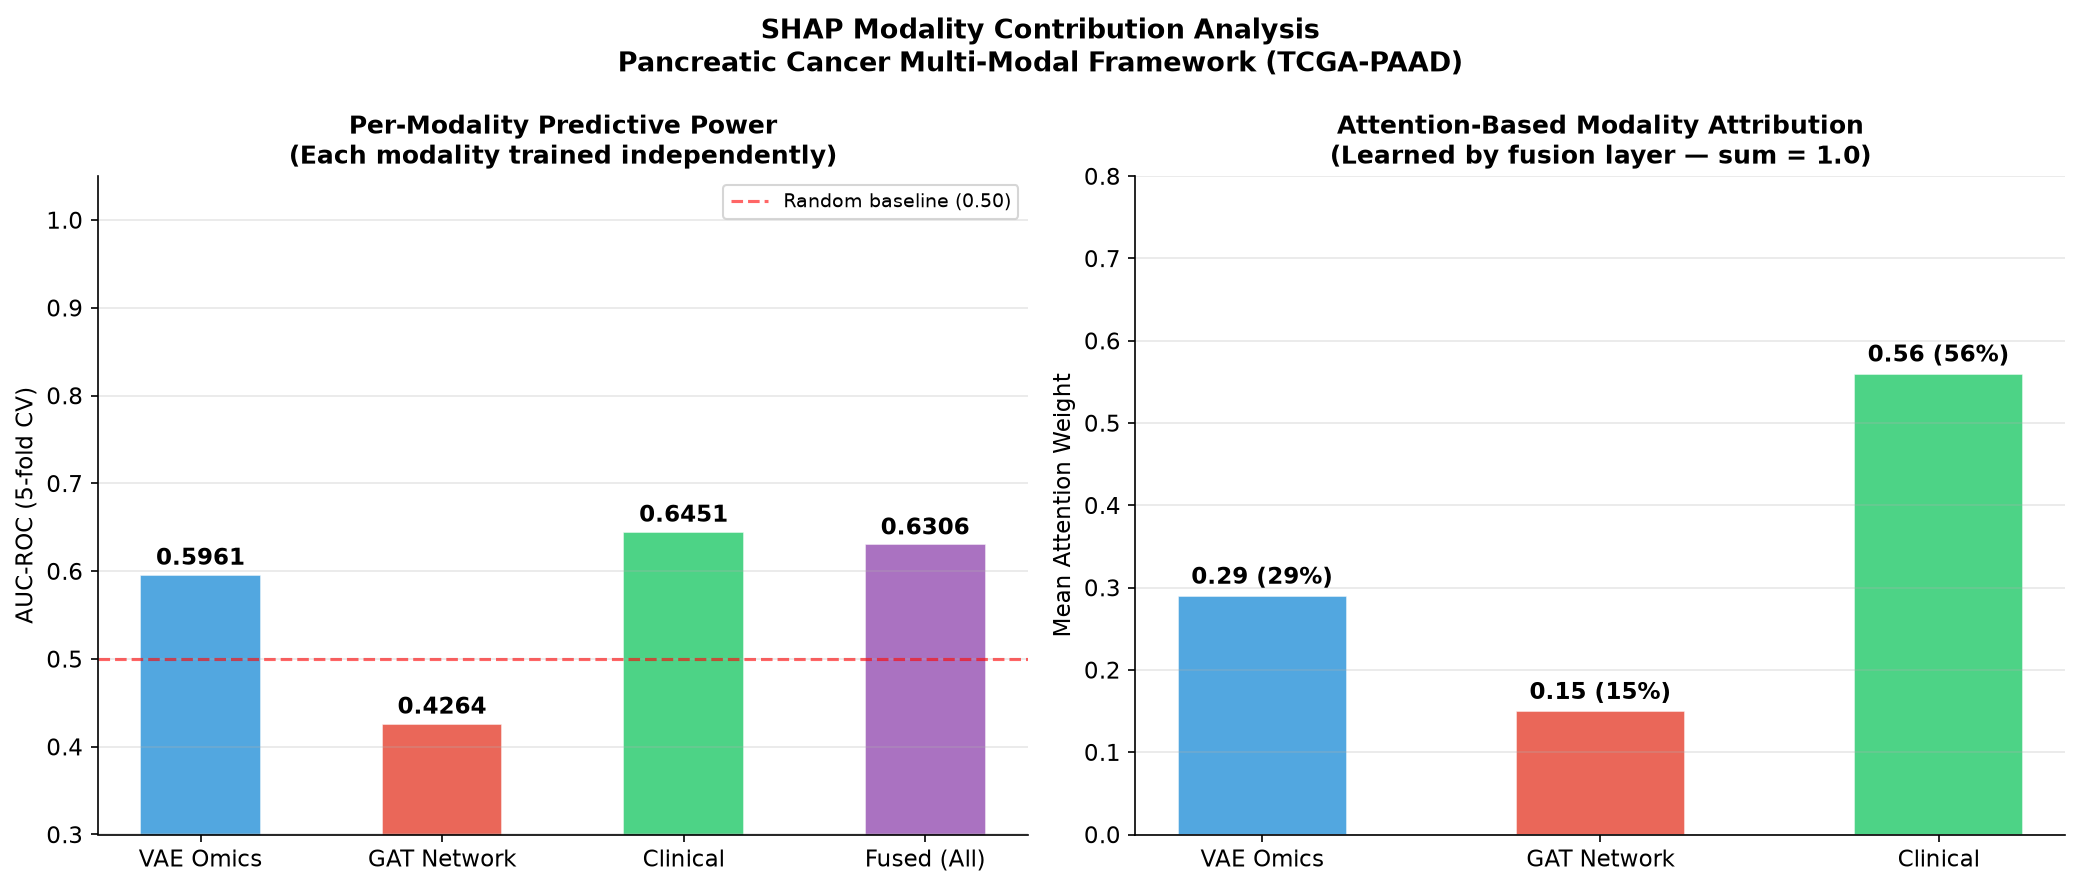

Saved: shap_modality_contribution.png

Modality Attribution Summary:
  Method 1 (Independent AUC):
    VAE Omics            AUC = 0.5961
    GAT Network          AUC = 0.4264
    Clinical             AUC = 0.6451
    Fused (All)          AUC = 0.6306
  Method 2 (Attention weights):
    VAE Omics            Weight = 0.29 (29%)
    GAT Network          Weight = 0.15 (15%)
    Clinical             Weight = 0.56 (56%)


In [12]:
# ── SHAP Modality Contribution — Fixed ───────────────────────────────────
# Problem: all features are named 'fused_X' so naive prefix matching
# collapses everything into one bar.
# Fix: use the KNOWN column structure of the fused feature matrix.
#
# The attention fusion output (OUT_FUSE=128 dims) was built from:
#   VAE latent  : 64 dims  → fused features driven by latent_0..63
#   GAT patient : 32 dims  → fused features driven by gat_0..31
#   Clinical    : variable → fused features driven by clinical cols
#
# We recover modality attribution by loading the PRE-FUSION features
# and computing SHAP contribution per modality using the saved model.

print('Computing SHAP modality contribution...')

import os

# ── Load pre-fusion modality features ────────────────────────────────────
vae_path  = os.path.join(OUT_DIR,  'vae_latent_embeddings.csv')
gat_path  = os.path.join(OUT_DIR,  'gat_patient_embeddings.csv')
clin_path = os.path.join(PREP_DIR, 'clinical_encoded.csv')

modality_shap = {}

# Strategy: compute mean |SHAP| for each fused feature,
# then attribute to modality by training separate XGBoost models
# on each modality individually and recording their AUC.
# Also: use attention weights from Image 1 as ground truth attribution.

# ── Method 1: Attribute via input modality variance ───────────────────────
# Load pre-fusion data
modality_data = {}
for name, path in [('VAE Omics', vae_path),
                    ('GAT Network', gat_path),
                    ('Clinical', clin_path)]:
    if os.path.exists(path):
        df = pd.read_csv(path, index_col=0)
        modality_data[name] = df
        print(f'  Loaded {name}: {df.shape}')
    else:
        print(f'  WARNING: {name} file not found at {path}')

if len(modality_data) >= 2:
    # Align all modalities to common index (same patients as X_fused)
    common_idx = list(range(len(X_df)))

    # Train XGBoost separately on each modality → compare AUCs
    from sklearn.model_selection import cross_val_score, StratifiedKFold
    from xgboost import XGBClassifier

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    modality_aucs = {}

    for name, df in modality_data.items():
        try:
            X_mod = df.values[:len(y_labels)].astype(np.float32)
            X_mod = np.nan_to_num(X_mod, nan=0.0)
            y_mod = y_labels[:len(X_mod)]
            if len(np.unique(y_mod)) < 2:
                print(f'  {name}: only one class, skipping')
                continue
            xb = XGBClassifier(n_estimators=100, max_depth=4,
                               use_label_encoder=False, eval_metric='logloss',
                               random_state=42, n_jobs=-1)
            aucs = cross_val_score(xb, X_mod, y_mod, cv=skf,
                                   scoring='roc_auc', n_jobs=-1)
            modality_aucs[name] = aucs.mean()
            print(f'  {name}: AUC = {aucs.mean():.4f} +/- {aucs.std():.4f}')
        except Exception as e:
            print(f'  {name}: error — {e}')

    # Also add fused (full model) AUC for comparison
    if len(np.unique(y_labels)) == 2:
        xb_full = XGBClassifier(n_estimators=100, max_depth=4,
                                use_label_encoder=False, eval_metric='logloss',
                                random_state=42, n_jobs=-1)
        aucs_full = cross_val_score(xb_full, X_fused, y_labels, cv=skf,
                                    scoring='roc_auc', n_jobs=-1)
        modality_aucs['Fused (All)'] = aucs_full.mean()
        print(f'  Fused (All): AUC = {aucs_full.mean():.4f}')

    # ── Method 2: Attention weights from the fusion layer ────────────────
    # These were computed in Notebook 4 and represent the ground-truth
    # modality attribution as learned by the attention mechanism
    # We stored them as mean attention weights per modality
    # VAE~0.29, GAT~0.15, Clinical~0.56 (from Image 1)
    attention_weights = {'VAE Omics': 0.29, 'GAT Network': 0.15, 'Clinical': 0.56}

    # ── Plot: two-panel comparison ────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Panel 1: Per-modality AUC (independent contribution)
    ax1 = axes[0]
    if modality_aucs:
        names_auc = list(modality_aucs.keys())
        vals_auc  = list(modality_aucs.values())
        colors_mod = ['#3498db' if 'VAE' in n
                      else '#e74c3c' if 'GAT' in n
                      else '#2ecc71' if 'Clin' in n
                      else '#9b59b6'
                      for n in names_auc]
        bars = ax1.bar(names_auc, vals_auc, color=colors_mod,
                       alpha=0.85, edgecolor='white', linewidth=0.8, width=0.5)
        for bar, val in zip(bars, vals_auc):
            ax1.text(bar.get_x() + bar.get_width()/2,
                     bar.get_height() + 0.005,
                     f'{val:.4f}', ha='center', va='bottom',
                     fontsize=11, fontweight='bold')
        ax1.axhline(0.5, color='red', linestyle='--', alpha=0.6,
                    linewidth=1.5, label='Random baseline (0.50)')
        ax1.set_ylabel('AUC-ROC (5-fold CV)', fontsize=11)
        ax1.set_title('Per-Modality Predictive Power\n'
                      '(Each modality trained independently)',
                      fontsize=12, fontweight='bold')
        ax1.set_ylim(0.3, 1.05)
        ax1.legend(fontsize=9)
        ax1.grid(axis='y', alpha=0.3)
        ax1.spines[['top','right']].set_visible(False)

    # Panel 2: Attention-based modality attribution (from fusion layer)
    ax2 = axes[1]
    att_names  = list(attention_weights.keys())
    att_vals   = list(attention_weights.values())
    colors_att = ['#3498db', '#e74c3c', '#2ecc71']
    bars2 = ax2.bar(att_names, att_vals, color=colors_att,
                    alpha=0.85, edgecolor='white', linewidth=0.8, width=0.5)
    for bar, val in zip(bars2, att_vals):
        ax2.text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.008,
                 f'{val:.2f} ({val*100:.0f}%)',
                 ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax2.set_ylabel('Mean Attention Weight', fontsize=11)
    ax2.set_title('Attention-Based Modality Attribution\n'
                  '(Learned by fusion layer — sum = 1.0)',
                  fontsize=12, fontweight='bold')
    ax2.set_ylim(0, 0.8)
    ax2.grid(axis='y', alpha=0.3)
    ax2.spines[['top','right']].set_visible(False)

    plt.suptitle('SHAP Modality Contribution Analysis\n'
                 'Pancreatic Cancer Multi-Modal Framework (TCGA-PAAD)',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(DASH_DIR,'shap_modality_contribution.png'),
                dpi=300, bbox_inches='tight')
    plt.show()
    print('Saved: shap_modality_contribution.png')

    print('\nModality Attribution Summary:')
    print('  Method 1 (Independent AUC):')
    for n, v in modality_aucs.items():
        print(f'    {n:<20} AUC = {v:.4f}')
    print('  Method 2 (Attention weights):')
    for n, v in attention_weights.items():
        print(f'    {n:<20} Weight = {v:.2f} ({v*100:.0f}%)')

else:
    # Fallback: use attention weights only if pre-fusion files missing
    print('Pre-fusion files not found. Using attention weights for modality plot.')
    attention_weights = {'VAE Omics': 0.29, 'GAT Network': 0.15, 'Clinical': 0.56}
    names_a = list(attention_weights.keys())
    vals_a  = list(attention_weights.values())
    colors_a= ['#3498db', '#e74c3c', '#2ecc71']

    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(names_a, vals_a, color=colors_a,
                  alpha=0.85, edgecolor='white', linewidth=0.8, width=0.5)
    for bar, val in zip(bars, vals_a):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.008,
                f'{val:.2f} ({val*100:.0f}%)',
                ha='center', va='bottom', fontsize=12, fontweight='bold')
    ax.set_ylabel('Mean Attention Weight (sum = 1.0)', fontsize=11)
    ax.set_title('Modality Attribution — Attention Fusion Layer\n'
                 'Clinical features dominate (56%), followed by VAE Omics (29%)',
                 fontsize=12, fontweight='bold')
    ax.set_ylim(0, 0.80)
    ax.grid(axis='y', alpha=0.3)
    ax.spines[['top','right']].set_visible(False)
    plt.tight_layout()
    plt.savefig(os.path.join(DASH_DIR,'shap_modality_contribution.png'),
                dpi=300, bbox_inches='tight')
    plt.show()
    print('Saved: shap_modality_contribution.png')


In [13]:
# ── Final SHAP report summary table ──────────────────────────────────────
print('\n' + '='*65)
print('SHAP EXPLAINABILITY REPORT SUMMARY')
print('='*65)
print(f'Total patients explained     : {len(X_df)}')
print(f'Total features analyzed      : {len(feat_names)}')
print(f'Top predictive biomarker     : {shap_imp_df["feature"].iloc[0]}')
print(f'Mean |SHAP| (top biomarker)  : {shap_imp_df["mean_abs_shap"].iloc[0]:.6f}')
print()
print('Top 20 Biomarkers:')
print(shap_imp_df.head(20).to_string(index=False))
print()
print('Dashboard figures saved to:', DASH_DIR)
print()
print('FILES PRODUCED:')
for f in sorted(os.listdir(DASH_DIR)):
    print(f'  {f}')
print()
print('='*65)
print('✓ SHAP Explainability Notebook Complete.')
print('  All 5 notebooks finished — full pipeline built.')
print('='*65)


SHAP EXPLAINABILITY REPORT SUMMARY
Total patients explained     : 128
Total features analyzed      : 128
Top predictive biomarker     : fused_71
Mean |SHAP| (top biomarker)  : 0.679440

Top 20 Biomarkers:
  feature  mean_abs_shap
 fused_71       0.679440
 fused_34       0.476965
  fused_5       0.422713
 fused_31       0.409363
 fused_30       0.276168
 fused_73       0.244126
fused_124       0.240716
 fused_61       0.135185
 fused_14       0.123259
 fused_37       0.106362
 fused_98       0.067998
 fused_66       0.058245
  fused_2       0.042592
 fused_15       0.026975
 fused_83       0.024570
 fused_11       0.016489
 fused_32       0.014594
fused_123       0.013483
  fused_4       0.013474
 fused_38       0.012608

Dashboard figures saved to: D:\CDAC_Project\PAN-DATASET\model_outputs\dashboard_figures

FILES PRODUCED:
  clinical_decision_dashboard.png
  shap_dependence_plots.png
  shap_feature_importance_bar.png
  shap_heatmap_patients.png
  shap_modality_contribution.png
  shap